# Semana 10 — pipeline multitarea

Proyecto PENGWIN, Analítica de Datos (UAO, 2026-2). Este notebook recorre lo que se hizo en la
Semana 10 y **lee los resultados guardados** en `outputs/s10/`: no entrena ni infiere, así que
corre en cualquier equipo con `pandas` y `matplotlib`, sin GPU y sin PyTorch.

- Cada tabla sale de un JSON que dejó `train_s10.py`, `evaluate_volumes.py` o `infer_volume.py`.
- Para repetir un entrenamiento hace falta GPU; los comandos exactos están en la
  sección 3 del `README.md`.
- El porqué de cada decisión está en `docs/decisiones_semana10.md` (bitácora).

**Resultado:** el modelo final (H6) cumple los nueve objetivos del enunciado en test, con una
salvedad sobre cómo se obtuvo esa cifra que se explica en la sección 7.

> Uso exclusivamente académico. Este sistema no es un dispositivo médico.

In [1]:
import json, sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import resumen_s10 as r

%matplotlib inline
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
print("Resultados leídos de", r.S10.relative_to(RAIZ), "·", len(list(r.S10.glob("*.json"))), "archivos JSON")

Resultados leídos de outputs\s10 · 117 archivos JSON


## 0. Entorno y pruebas

Las pruebas automáticas cubren el modelo, la pérdida, las métricas, el post-proceso, las distancias
y la orientación. Tardan cerca de un minuto y necesitan PyTorch; por eso aquí quedan apagadas por
defecto.

In [2]:
CORRER_PRUEBAS = False   # True para ejecutar `python -m unittest discover -s tests`

if CORRER_PRUEBAS:
    import subprocess
    salida = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests"],
                            cwd=RAIZ, capture_output=True, text=True)
    print(salida.stderr[-400:])
else:
    print("Pruebas no ejecutadas aquí. Comando: python -m unittest discover -s tests -v")

Pruebas no ejecutadas aquí. Comando: python -m unittest discover -s tests -v


## 1. De dónde se parte

La Semana 9 dejó el backbone propio con CBAM, la cabeza de detección por grid y el NMS propio. El
primer intento de la Semana 10 (`w10g_384neg`) quedó como **línea base**: se volvió a medir con la
regla nueva, sobre todos los cortes de los 15 casos de validación y no sobre una muestra del centro.

In [3]:
r.tabla_objetivos([("Línea base", "linea_base_val")])

,Objetivo,Línea base,Línea base cumple
Métrica,,,
F1 de clasificación (macro),0.85,0.970,sí
AUC de clasificación (macro),0.85,0.993,sí
IoU medio de detección (caja refinada),0.65,0.881,sí
mAP50 de detección (refinada),0.65,0.874,sí
mAP50:95 de detección (refinada),0.40,0.781,sí
Dice de segmentación semántica (macro),0.85,0.956,sí
IoU de segmentación semántica (macro),0.70,0.916,sí
Dice por fragmento,0.85,0.834,NO
IoU por fragmento,0.70,0.762,sí


**Lectura.** La línea base ya cumplía todo menos el Dice por fragmento (0.834 frente a 0.85). Ese
es el número que guía toda la semana.

## 2. Datos

- 100 casos PENGWIN, partidos por paciente en 70 / 15 / 15 (semilla 42, `data/splits.json`).
- Caché por caso a 384 × 384 (`src/build_case_cache.py`): se usan **todos** los cortes del volumen y
  se incluyen cortes sin hueso al entrenar (15 % de cada época).
- Etiquetas del dataset tal cual: 1–10 sacro, 11–20 coxal izquierdo, 21–30 coxal derecho; el menor
  ID de cada rango es el fragmento principal.

In [4]:
import orientacion

splits = json.loads((RAIZ / "data" / "splits.json").read_text())
filas = []
for nombre in ("train", "val", "test"):
    casos = [str(c).zfill(3) for c in splits[nombre]]
    girados = sum(orientacion.is_rotated(c) for c in casos)
    filas.append({"partición": nombre, "casos": len(casos), "guardados girados 180°": girados})
tabla = pd.DataFrame(filas).set_index("partición")
tabla.loc["total"] = tabla.sum()
print("Cortes evaluados: validación", r.resumen("d5_ema_w32_e60_s42_val")["n_slices"],
      "· test", r.resumen("TEST_d5_s42_tta")["n_slices"])
tabla

Cortes evaluados: validación 5047 · test 4664


,casos,guardados girados 180°
partición,,
train,70,22
val,15,10
test,15,2
total,100,34


**Lectura.** Un tercio de los volúmenes (34 de 100) está guardado girado 180° en el plano. Lo dice
la cabecera del `.mha` (`TransformMatrix = -1 0 0 0 -1 0 0 0 1`), pero al leer el arreglo con
SimpleITK esa información se pierde. Durante casi toda la semana el modelo recibió las dos
orientaciones mezcladas sin saberlo; se descubrió al analizar los fallos de test (sección 6b).
Además el reparto no es parejo: 10 de los 15 casos de validación están girados y solo 2 de los 15
de test. La partición es por paciente con semilla fija y no se tocó.

## 3. Arquitectura

Un solo modelo con backbone compartido y tres cabezas, todo propio:

| Pieza | Qué hace |
|---|---|
| Backbone | Convolucional, 32 canales base, CBAM (canal y espacial) en una etapa antes de bifurcar |
| Clasificación | Qué regiones aparecen en el corte: sacro, coxal izquierdo, coxal derecho |
| Detección | Grid propio, una celda por región, NMS propio |
| Segmentación semántica | Fondo y las tres regiones |
| Segmentación de instancia | Dentro de cada región: fragmento principal o secundario. Los fragmentos se separan después por componentes conexas |

Sin YOLO, Detectron2 ni Mask R-CNN. Las cabezas se entrenan desde cero.

In [5]:
try:
    import torch
    from week10_multitask import PengwinMultiTaskModel
    modelo = PengwinMultiTaskModel(base_channels=32, instance_mode="primary", use_cbam=True, cbam_stages=1)
    salida = modelo(torch.zeros(1, 1, 384, 384))
    print(f"Parámetros: {sum(p.numel() for p in modelo.parameters()):,}")
    for nombre, tensor in salida.items():
        if hasattr(tensor, "shape"):
            print(f"  {nombre:14s} {tuple(tensor.shape)}")
except ImportError:
    print("PyTorch no está instalado en este entorno.")
    print("Referencia del entrenamiento: 2,736,958 parámetros (ancho 32, CBAM en 1 etapa).")

Parámetros: 2,736,958
  classification (1, 3)
  detection      (1, 24, 24, 8)
  semantic       (1, 4, 384, 384)
  instance       (1, 7, 384, 384)
  boundary       (1, 1, 384, 384)
  centers        (1, 3, 384, 384)
  offsets        (1, 2, 384, 384)


## 4. Pérdida compuesta y λ

La pérdida suma un término por tarea. Pesos por defecto: detección 1, clasificación 0.5, semántica 2
(más Dice semántico 1), instancia 1 (más Dice de instancia 1), borde 1; los píxeles de fragmentos
secundarios pesan ×3. Se probó subir instancia y borde ×2 y bajar detección ×0.5.

In [6]:
r.tabla_modelos([
    ("c2, λ por defecto", "c2_w32_cbam1_sec3_e60_s42_val"),
    ("c2, λ instancia y borde ×2", "colab_w32_lam_e60_s42_val"),
    ("D5 (c2 + EMA), λ por defecto", "d5_ema_w32_e60_s42_val"),
    ("D5, λ instancia y borde ×2 (F2)", "f2_ema_lam_w32_e60_s42_val"),
])

,F1,mAP50,mAP50:95,mAP50 cruda,Dice sem.,Dice inst.,Primario,Secundario,Sec. sin pareja
Modelo,,,,,,,,,
"c2, λ por defecto",0.988,0.962,0.889,0.875,0.969,0.849,0.903,0.687,0.102
"c2, λ instancia y borde ×2",0.985,0.964,0.896,0.832,0.967,0.849,0.907,0.676,0.134
"D5 (c2 + EMA), λ por defecto",0.988,0.959,0.883,0.868,0.968,0.851,0.900,0.703,0.090
"D5, λ instancia y borde ×2 (F2)",0.985,0.962,0.894,0.827,0.968,0.855,0.907,0.701,0.110


**Lectura.** Cambiar los λ no mueve las instancias más que el ruido (sección 5) y empeora la
detección cruda. Se dejan los valores por defecto.

## 5. Receta base y ruido entre semillas

Antes de comparar nada se midió cuánto cambia el resultado solo por la semilla. Esa variación es el
**ruido**: un cambio se acepta únicamente si lo supera.

In [7]:
familias = {
    "B1 (8 canales)": ["b1_cbam1_sec3_e80_s42_val", "b1s43_cbam1_sec3_e80_s43_val", "b1s44_cbam1_sec3_e80_s44_val"],
    "c2 (32 canales)": ["c2_w32_cbam1_sec3_e60_s42_val", "c2s43_w32_cbam1_sec3_e60_s43_val", "c2s44_w32_cbam1_sec3_e60_s44_val"],
    "D5 (c2 + EMA)": ["d5_ema_w32_e60_s42_val", "d5_ema_w32_e60_s43_val", "d5_ema_w32_e60_s44_val"],
    "H6 (final)": ["h6_auggeo_rot35_canon_ema_w32_e60_s42_val", "h6_auggeo_rot35_canon_ema_w32_e60_s43_val",
                   "h6_auggeo_rot35_canon_ema_w32_e60_s44_val"],
}
filas = []
for nombre, corridas in familias.items():
    inst = pd.Series([r.resumen(c)["instance_dice_matched"] for c in corridas])
    sec = pd.Series([r.resumen(c)["instance_dice_secondary"] for c in corridas])
    filas.append({"Receta": nombre, "Dice inst. por semilla": " / ".join(f"{v:.3f}" for v in inst),
                  "media": round(inst.mean(), 3), "desviación": round(inst.std(ddof=0), 3),
                  "Secundario (media)": round(sec.mean(), 3), "Secundario (desviación)": round(sec.std(ddof=0), 3)})
pd.DataFrame(filas).set_index("Receta")

,Dice inst. por semilla,media,desviación,Secundario (media),Secundario (desviación)
Receta,,,,,
B1 (8 canales),0.835 / 0.826 / 0.826,0.829,0.004,0.645,0.012
c2 (32 canales),0.849 / 0.846 / 0.854,0.850,0.003,0.687,0.009
D5 (c2 + EMA),0.851 / 0.855 / 0.854,0.853,0.002,0.712,0.009
H6 (final),0.869 / 0.868 / 0.872,0.870,0.002,0.768,0.007


**Lectura.** Entre semillas el Dice por fragmento se mueve unos ±0.004 y el de secundarios ±0.012.
Cualquier diferencia menor que eso no es evidencia.

## 6. Exploración: un cambio a la vez

Validación, 15 casos, TTA espejo. Cada fila cambia una sola cosa frente a la receta de arriba.

In [8]:
r.tabla_modelos([
    ("Línea base w10g_384neg", "linea_base_val"),
    ("B0 sin CBAM (8 canales, 40 ép.)", "b0_cbam0_s42_val"),
    ("B0 CBAM en 1 etapa", "b0_cbam1_s42_val"),
    ("B0 CBAM en 3 etapas + γ", "b0_cbam3g_s42_val"),
    ("B1: 8 canales, secundarios ×3", "b1_cbam1_sec3_e80_s42_val"),
    ("B2: secundarios ×6", "b2_cbam1_sec6_e50_s42_val"),
    ("B1 + peso por fractura", "colab_cbam1_sec3_frac2_s42_val"),
    ("Instancia con 31 clases (ids)", "colab_ids_cbam1_sec3_e80_s42_val"),
    ("c1: 16 canales", "c1_w16_cbam1_sec3_e80_s42_val"),
    ("c2: 32 canales", "c2_w32_cbam1_sec3_e60_s42_val"),
    ("48 canales", "colab_w48_cbam1_sec3_e60_s42_val"),
    ("D1: c2 + contexto 2.5D", "d1_ctx1_w32_e60_s42_val"),
    ("D2: c2 + pérdida focal", "d2_focal2_w32_e60_s42_val"),
    ("D3: c2 + Tversky", "d3_tversky07_w32_e60_s42_val"),
    ("D4: c2 + supervisión profunda", "d4_ds04_w32_e60_s42_val"),
    ("D5: c2 + EMA", "d5_ema_w32_e60_s42_val"),
    ("D6: c2 + sobremuestreo de secundarios", "d6_oversample3_w32_e60_s42_val"),
    ("E1: c2 + backbone preentrenado (Intel)", "e1_intel_w32_e60_s42_val"),
    ("E2: D5 + backbone preentrenado (Intel)", "e2_intel_ema_w32_e60_s42_val"),
    ("Ensamble de 3 semillas de D5", "g1_ens3_ema_val"),
])

,F1,mAP50,mAP50:95,mAP50 cruda,Dice sem.,Dice inst.,Primario,Secundario,Sec. sin pareja
Modelo,,,,,,,,,
Línea base w10g_384neg,0.970,0.874,0.781,0.694,0.956,0.834,0.879,0.702,0.084
"B0 sin CBAM (8 canales, 40 ép.)",0.966,0.900,0.796,0.735,0.957,0.824,0.883,0.649,0.094
B0 CBAM en 1 etapa,0.963,0.926,0.835,0.799,0.960,0.821,0.880,0.642,0.104
B0 CBAM en 3 etapas + γ,0.968,0.907,0.814,0.805,0.959,0.823,0.884,0.642,0.110
"B1: 8 canales, secundarios ×3",0.971,0.935,0.850,0.805,0.963,0.835,0.894,0.661,0.105
B2: secundarios ×6,0.973,0.918,0.834,0.804,0.963,0.832,0.883,0.681,0.096
B1 + peso por fractura,0.980,0.945,0.867,0.827,0.965,0.832,0.895,0.642,0.146
Instancia con 31 clases (ids),0.970,0.933,0.844,0.814,0.962,0.787,0.896,0.460,0.450
c1: 16 canales,0.986,0.955,0.886,0.871,0.969,0.839,0.903,0.649,0.152


**Lectura.** De unos quince cambios, dos superan el ruido: el **ancho del backbone** (8 → 32 canales)
y **EMA**, que sube sobre todo los secundarios. Contexto 2.5D, focal, Tversky, supervisión profunda,
sobremuestreo, más peso a secundarios, 48 canales y la instancia con 31 clases no ayudan o empeoran.
Con D5 el Dice por fragmento queda en 0.851–0.855 según la semilla: justo en el objetivo.

## 6b. Serie H: por qué fallaba y cómo se arregló

Con D5 congelado se evaluó test una vez (sección 7) y dio 0.845. Dos casos lo hundían: el 012, con
el paciente girado unos 26° en el escáner, y el 039. El análisis mostró dos causas que ningún
experimento anterior había tocado:

1. El entrenamiento no tenía **ningún aumento geométrico**: la red memorizaba (la pérdida de
   entrenamiento seguía bajando con la validación plana desde la época 30).
2. La **orientación mezclada** de la sección 2.

In [9]:
print("Pérdida de entrenamiento y Dice por fragmento (subconjunto de validación) por época")
curvas = pd.DataFrame({
    "D5 pérdida": r.historia("d5_ema_w32_e60_s42").set_index("epoch")["loss"],
    "D5 Dice inst.": r.historia("d5_ema_w32_e60_s42").set_index("epoch")["instance_dice_matched"],
    "H6 pérdida": r.historia("h6_auggeo_rot35_canon_ema_w32_e60_s42").set_index("epoch")["loss"],
    "H6 Dice inst.": r.historia("h6_auggeo_rot35_canon_ema_w32_e60_s42").set_index("epoch")["instance_dice_matched"],
}).round(3)
curvas

Pérdida de entrenamiento y Dice por fragmento (subconjunto de validación) por época


,D5 pérdida,D5 Dice inst.,H6 pérdida,H6 Dice inst.
epoch,,,,
1,4.626,0.563,5.086,0.529
10,0.860,0.818,0.974,0.817
20,0.707,0.840,0.843,0.841
30,0.593,0.849,0.744,0.853
40,0.524,0.851,0.674,0.863
50,0.486,0.849,0.635,0.868
60,0.483,0.847,0.624,0.870


In [10]:
serie_h = [
    ("D5 (referencia)", "d5_ema_w32_e60_s42_val"),
    ("H1: + aumento geométrico (rotación ±12°)", "h1_auggeo_ema_w32_e60_s42_val"),
    ("H1, semilla 43", "h1_auggeo_ema_w32_e60_s43_val"),
    ("H2: caché que conserva la proporción", "h2_pad_ema_w32_e60_s42_val"),
    ("H4: + orientación canónica, sin aumento", "h4_canon_ema_w32_e60_s42_val"),
    ("H5: aumento + orientación canónica", "h5_auggeo_canon_ema_w32_e60_s42_val"),
    ("H5, semilla 43", "h5_auggeo_canon_ema_w32_e60_s43_val"),
    ("H6: H5 con rotación ±35°", "h6_auggeo_rot35_canon_ema_w32_e60_s42_val"),
    ("H6, semilla 43", "h6_auggeo_rot35_canon_ema_w32_e60_s43_val"),
    ("H6, semilla 44", "h6_auggeo_rot35_canon_ema_w32_e60_s44_val"),
    ("Ensamble de las 3 semillas de H6", "h6_ensamble3_val"),
]
r.tabla_modelos(serie_h)

,F1,mAP50,mAP50:95,mAP50 cruda,Dice sem.,Dice inst.,Primario,Secundario,Sec. sin pareja
Modelo,,,,,,,,,
D5 (referencia),0.988,0.959,0.883,0.868,0.968,0.851,0.900,0.703,0.090
H1: + aumento geométrico (rotación ±12°),0.988,0.969,0.902,0.915,0.970,0.864,0.905,0.743,0.075
"H1, semilla 43",0.989,0.968,0.902,0.880,0.969,0.865,0.903,0.750,0.065
H2: caché que conserva la proporción,0.986,0.961,0.890,0.884,0.969,0.857,0.902,0.723,0.104
"H4: + orientación canónica, sin aumento",0.991,0.971,0.897,0.873,0.970,0.861,0.901,0.742,0.088
H5: aumento + orientación canónica,0.992,0.976,0.912,0.922,0.971,0.873,0.908,0.769,0.062
"H5, semilla 43",0.989,0.969,0.903,0.893,0.971,0.869,0.904,0.762,0.064
H6: H5 con rotación ±35°,0.992,0.971,0.904,0.887,0.971,0.869,0.905,0.764,0.069
"H6, semilla 43",0.990,0.969,0.900,0.877,0.971,0.868,0.903,0.762,0.066


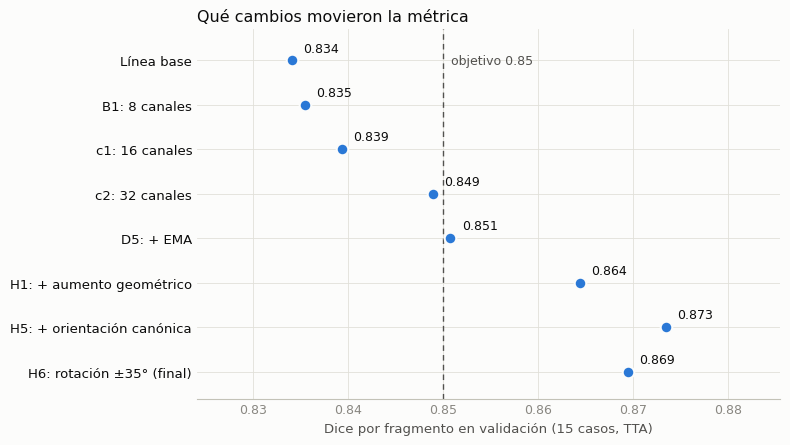

In [11]:
fig = r.figura_progresion([
    ("Línea base", "linea_base_val"),
    ("B1: 8 canales", "b1_cbam1_sec3_e80_s42_val"),
    ("c1: 16 canales", "c1_w16_cbam1_sec3_e80_s42_val"),
    ("c2: 32 canales", "c2_w32_cbam1_sec3_e60_s42_val"),
    ("D5: + EMA", "d5_ema_w32_e60_s42_val"),
    ("H1: + aumento geométrico", "h1_auggeo_ema_w32_e60_s42_val"),
    ("H5: + orientación canónica", "h5_auggeo_canon_ema_w32_e60_s42_val"),
    ("H6: rotación ±35° (final)", "h6_auggeo_rot35_canon_ema_w32_e60_s42_val"),
])
plt.show()

H5 y H6 empatan en validación normal. Para decidir se usó una **prueba de estrés**: la misma
validación, girada antes de entrar al modelo (`evaluate_volumes.py --stress`). La regla se escribió
antes de ver el número: se queda H6 si con giro de 30° supera con claridad a H5.

,sin girar,girada 30°,girada 60°
D5,0.851,0.559,0.127
H1,0.864,0.771,0.212
H5,0.873,0.807,0.218
H6,0.869,0.854,0.734


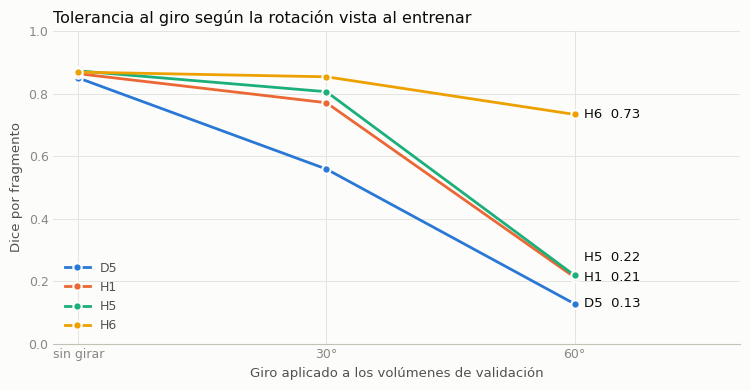

In [12]:
estres = pd.DataFrame({
    "sin girar": {"D5": r.resumen("d5_ema_w32_e60_s42_val")["instance_dice_matched"],
                  "H1": r.resumen("h1_auggeo_ema_w32_e60_s42_val")["instance_dice_matched"],
                  "H5": r.resumen("h5_auggeo_canon_ema_w32_e60_s42_val")["instance_dice_matched"],
                  "H6": r.resumen("h6_auggeo_rot35_canon_ema_w32_e60_s42_val")["instance_dice_matched"]},
    "girada 30°": {m: r.resumen(f"estres2_{m.lower()}_rot_30")["instance_dice_matched"] for m in ("D5", "H1", "H5", "H6")},
    "girada 60°": {"D5": r.resumen("estres_d5_rot60")["instance_dice_matched"],
                   **{m: r.resumen(f"estres2_{m.lower()}_rot_60")["instance_dice_matched"] for m in ("H1", "H5", "H6")}},
}).round(3)
display(estres)
fig = r.figura_estres([
    ("D5", [(0, "d5_ema_w32_e60_s42_val"), (30, "estres2_d5_rot_30"), (60, "estres_d5_rot60")]),
    ("H1", [(0, "h1_auggeo_ema_w32_e60_s42_val"), (30, "estres2_h1_rot_30"), (60, "estres2_h1_rot_60")]),
    ("H5", [(0, "h5_auggeo_canon_ema_w32_e60_s42_val"), (30, "estres2_h5_rot_30"), (60, "estres2_h5_rot_60")]),
    ("H6", [(0, "h6_auggeo_rot35_canon_ema_w32_e60_s42_val"), (30, "estres2_h6_rot_30"), (60, "estres2_h6_rot_60")]),
])
plt.show()

**Lectura y decisión.** El aumento geométrico y la orientación canónica aportan cada uno por
separado y se suman. Con giro de 30°, H6 da 0.854 y H5 0.807; girado, H6 rinde más que D5 sin girar.
**H6 es el modelo final.** El ensamble de sus tres semillas gana 0.003, dentro del ruido, así que
se usa un solo modelo.

Se probó también detectar el giro con un algoritmo geométrico (`orientacion.estimate_angle`). Se
descartó: al revisar a ojo los casos que marcaba como inclinados, casi todos eran pacientes bien
colocados (`outputs/s10/contacto_orientacion.png`).

## 7. Modelo final contra los objetivos

Test se evaluó dos veces, y las dos cifras se reportan:

- **Primera (D5 s42).** Configuración congelada por escrito antes de mirar test. Es la cifra limpia.
- **Segunda (H6 s42).** Después de analizar los fallos de la primera. Ese análisis miró dos casos de
  test (012 y 039), así que no es una estimación independiente. El modelo, eso sí, se eligió solo
  con validación y con la prueba de estrés.

In [13]:
r.tabla_objetivos([("Test D5 (primera)", "TEST_d5_s42_tta"), ("Test H6 (segunda)", "TEST2_h6_s42_tta"),
                   ("Validación H6", "h6_auggeo_rot35_canon_ema_w32_e60_s42_val")])

,Objetivo,Test D5 (primera),Test D5 (primera) cumple,Test H6 (segunda),Test H6 (segunda) cumple,Validación H6,Validación H6 cumple
Métrica,,,,,,,
F1 de clasificación (macro),0.85,0.984,sí,0.990,sí,0.992,sí
AUC de clasificación (macro),0.85,0.998,sí,0.999,sí,0.999,sí
IoU medio de detección (caja refinada),0.65,0.898,sí,0.943,sí,0.949,sí
mAP50 de detección (refinada),0.65,0.920,sí,0.961,sí,0.971,sí
mAP50:95 de detección (refinada),0.40,0.853,sí,0.902,sí,0.904,sí
Dice de segmentación semántica (macro),0.85,0.949,sí,0.971,sí,0.971,sí
IoU de segmentación semántica (macro),0.70,0.904,sí,0.943,sí,0.944,sí
Dice por fragmento,0.85,0.845,NO,0.875,sí,0.869,sí
IoU por fragmento,0.70,0.781,sí,0.816,sí,0.808,sí


In [14]:
r.tabla_modelos([
    ("D5 s42 (primera evaluación)", "TEST_d5_s42_tta"),
    ("H6 s42 (modelo final)", "TEST2_h6_s42_tta"),
    ("H6 s43", "TEST2_h6_s43_tta"),
    ("H6 s44", "TEST2_h6_s44_tta"),
    ("Ensamble de las 3 semillas de H6", "TEST2_h6_ens3_tta"),
])

,F1,mAP50,mAP50:95,mAP50 cruda,Dice sem.,Dice inst.,Primario,Secundario,Sec. sin pareja
Modelo,,,,,,,,,
D5 s42 (primera evaluación),0.984,0.920,0.853,0.866,0.949,0.845,0.894,0.692,0.106
H6 s42 (modelo final),0.990,0.961,0.902,0.912,0.971,0.875,0.915,0.750,0.078
H6 s43,0.986,0.952,0.894,0.898,0.970,0.875,0.913,0.752,0.076
H6 s44,0.989,0.960,0.902,0.908,0.970,0.876,0.913,0.761,0.073
Ensamble de las 3 semillas de H6,0.990,0.963,0.907,0.912,0.972,0.879,0.916,0.761,0.075


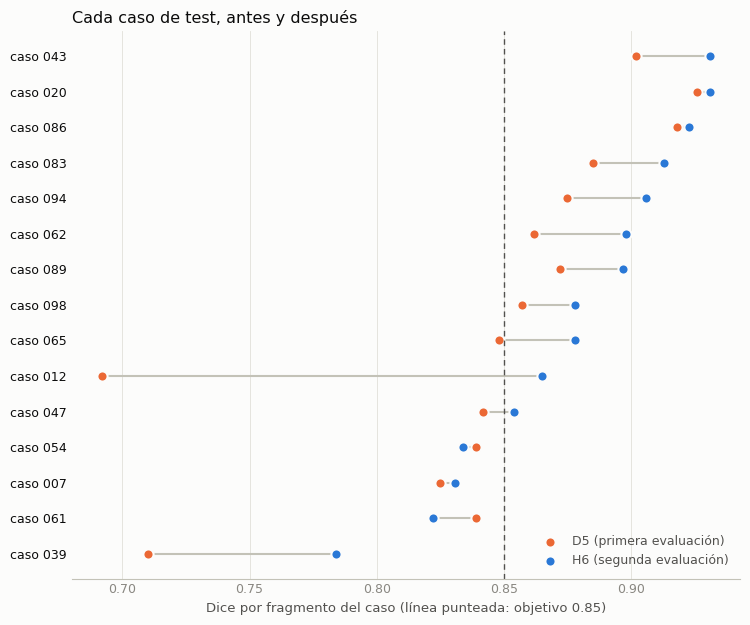

,D5,H6,cambio
012,0.692,0.865,0.173
039,0.710,0.784,0.074
062,0.862,0.898,0.036
094,0.875,0.906,0.031
065,0.848,0.878,0.030
043,0.902,0.931,0.029
083,0.885,0.913,0.028
089,0.872,0.897,0.025
098,0.857,0.878,0.021
047,0.842,0.854,0.012


In [15]:
fig = r.figura_por_caso(("D5 (primera evaluación)", "TEST_d5_s42_tta"), ("H6 (segunda evaluación)", "TEST2_h6_s42_tta"))
plt.show()
r.tabla_por_caso([("D5", "TEST_d5_s42_tta"), ("H6", "TEST2_h6_s42_tta")]).assign(
    cambio=lambda t: (t["H6"] - t["D5"]).round(3)).sort_values("cambio", ascending=False)

**Lectura.** Con H6 se cumplen los nueve objetivos; el Dice por fragmento pasa de 0.845 a 0.875. Las
tres semillas dan lo mismo (0.875–0.876), así que no depende de la semilla. Mejora en 13 de los 15
casos; los dos que hundían el test suben de 0.692 a 0.865 (012) y de 0.710 a 0.784 (039). El 039
sigue siendo el peor.

## 8. Ablaciones obligatorias

Con y sin CBAM, con y sin transfer learning. Se midieron sobre c2 y sobre D5, **no sobre H6**: H6
comparte arquitectura, pérdida y λ con D5.

In [16]:
r.tabla_modelos([
    ("c2 con CBAM", "c2_w32_cbam1_sec3_e60_s42_val"),
    ("c2 sin CBAM (A1)", "a1_cbam0_w32_e60_s42_val"),
    ("D5 con CBAM", "d5_ema_w32_e60_s42_val"),
    ("D5 sin CBAM (F1)", "f1_ema_cbamnone_w32_e60_s42_val"),
    ("c2 sin preentrenar", "c2_w32_cbam1_sec3_e60_s42_val"),
    ("c2 con backbone preentrenado en Intel (E1)", "e1_intel_w32_e60_s42_val"),
    ("D5 sin preentrenar, s42", "d5_ema_w32_e60_s42_val"),
    ("D5 preentrenado, s42 (E2)", "e2_intel_ema_w32_e60_s42_val"),
    ("D5 sin preentrenar, s43", "d5_ema_w32_e60_s43_val"),
    ("D5 preentrenado, s43 (E2)", "e2s43_intel_ema_w32_e60_s43_val"),
])

,F1,mAP50,mAP50:95,mAP50 cruda,Dice sem.,Dice inst.,Primario,Secundario,Sec. sin pareja
Modelo,,,,,,,,,
c2 con CBAM,0.988,0.962,0.889,0.875,0.969,0.849,0.903,0.687,0.102
c2 sin CBAM (A1),0.976,0.954,0.878,0.879,0.968,0.847,0.901,0.686,0.107
D5 con CBAM,0.988,0.959,0.883,0.868,0.968,0.851,0.900,0.703,0.090
D5 sin CBAM (F1),0.975,0.946,0.872,0.875,0.968,0.851,0.903,0.696,0.103
c2 sin preentrenar,0.988,0.962,0.889,0.875,0.969,0.849,0.903,0.687,0.102
c2 con backbone preentrenado en Intel (E1),0.988,0.959,0.887,0.905,0.969,0.847,0.902,0.683,0.120
"D5 sin preentrenar, s42",0.988,0.959,0.883,0.868,0.968,0.851,0.900,0.703,0.090
"D5 preentrenado, s42 (E2)",0.984,0.948,0.872,0.872,0.966,0.851,0.897,0.714,0.095
"D5 sin preentrenar, s43",0.986,0.968,0.898,0.868,0.968,0.855,0.899,0.724,0.093


**Lectura.** CBAM aporta en clasificación (F1 +0.013) y en detección refinada (mAP50:95 +0.011); la
segmentación queda igual. El preentrenamiento en Intel Image no da una ganancia consistente: en
secundarios suma con la semilla 42 y resta con la 43.

## 9. Volumen: post-proceso 3D y distancia de separación

`infer_volume.py` apila las máscaras, separa los fragmentos en 3D por región y mide la distancia
mínima borde a borde de cada fragmento secundario al principal, en mm, con el spacing de la cabecera
(`scipy.ndimage.distance_transform_edt`). La misma medida se calcula sobre el ground truth.

In [17]:
r.tabla_distancias([("Validación D5", "d5_nofill_val15"), ("Validación H6", "h6_s42_nofill_val15"),
                    ("Test D5", "TEST_d5_s42_nofill"), ("Test H6", "TEST2_h6_s42_nofill")])

,Validación D5,Validación H6,Test D5,Test H6
Error medio (mm),0.518,0.185,2.956,1.277
Error p90 (mm),0.388,0.000,3.453,0.556
Correlación,0.925,0.972,0.543,0.818
Secundarios,41.000,41.000,41.000,41.000
Con distancia predicha,38.000,38.000,36.000,36.000
Dice 3D principal,0.911,0.921,0.909,0.931
Dice 3D secundario,0.605,0.701,0.682,0.756
Secundarios perdidos,0.047,0.050,0.056,0.078
ASSD (mm),5.113,4.084,3.022,2.056
HD95 (mm),22.809,17.992,16.334,11.553


In [18]:
frag = r.fragmentos_con_distancia("TEST2_h6_s42_nofill").dropna(subset=["error (mm)"])
print(len(frag), "fragmentos secundarios de test con distancia predicha;",
      int((frag["error (mm)"] > 1).sum()), "con error mayor a 1 mm")
frag.sort_values("error (mm)", ascending=False).head(6)

36 fragmentos secundarios de test con distancia predicha; 4 con error mayor a 1 mm


,caso,región,real (mm),predicha (mm),error (mm),Dice 3D
3,007,coxal_derecho,9.41,45.76,36.35,0.82
18,054,coxal_izquierdo,0.00,6.00,6.00,0.96
21,054,coxal_derecho,40.03,42.55,2.52,0.77
19,054,coxal_derecho,0.00,1.11,1.11,0.73
0,007,coxal_izquierdo,0.00,0.00,0.00,0.37
30,086,sacro,0.00,0.00,0.00,0.85


**Lectura.** La primera versión del post-proceso rellenaba el hueco entre fragmentos y dejaba todas
las distancias predichas en 0 mm; la cifra parecía buena porque casi todos los fragmentos reales
están en contacto. Se corrigió midiendo sobre el volumen sin relleno (`--distance-nofill`). Con H6,
en test el error medio es 1.28 mm y la correlación 0.82, pero un solo fragmento (caso 007) concentra
el 79 % del error; sin él sería 0.28 mm. Fragmentos en contacto miden 0 mm: es la limitación que el
enunciado pide declarar.

## 10. Línea base SAM zero-shot

SAM ViT-B no forma parte del sistema. Recibe como prompt la caja que predice nuestro detector y
devuelve una máscara; se compara contra nuestra máscara semántica dentro de la misma caja, sobre uno
de cada tres cortes con hueso. El enunciado pide la comparación sobre test.

In [19]:
def tabla_sam(nombre):
    sam = r.cargar(nombre)
    filas = {region: {"SAM Dice": v["sam"]["dice"], "SAM IoU": v["sam"]["iou"],
                      "Nuestro Dice": v["nuestro"]["dice"], "Nuestro IoU": v["nuestro"]["iou"], "pares": v["sam"]["n"]}
             for region, v in sam["regiones"].items()}
    filas["global"] = {"SAM Dice": sam["global_sam"]["dice"], "SAM IoU": sam["global_sam"]["iou"],
                       "Nuestro Dice": sam["global_nuestro"]["dice"], "Nuestro IoU": sam["global_nuestro"]["iou"],
                       "pares": sam["global_sam"]["n"]}
    print("Partición:", sam["split"], "·", sam["cortes"], "cortes")
    return pd.DataFrame(filas).T.round(3)

print("Test, con las cajas y la máscara de H6")
display(tabla_sam("sam_baseline_test_h6"))
pd.DataFrame({
    "SAM Dice": {"Test (H6)": r.cargar("sam_baseline_test_h6")["global_sam"]["dice"],
                 "Validación (H6)": r.cargar("sam_baseline_val_h6")["global_sam"]["dice"],
                 "Validación (D5)": r.cargar("sam_baseline_val")["global_sam"]["dice"]},
    "Nuestro Dice": {"Test (H6)": r.cargar("sam_baseline_test_h6")["global_nuestro"]["dice"],
                     "Validación (H6)": r.cargar("sam_baseline_val_h6")["global_nuestro"]["dice"],
                     "Validación (D5)": r.cargar("sam_baseline_val")["global_nuestro"]["dice"]},
}).round(3)

Test, con las cajas y la máscara de H6
Partición: test · 1181 cortes


,SAM Dice,SAM IoU,Nuestro Dice,Nuestro IoU,pares
sacro,0.792,0.690,0.884,0.820,766.0
coxal_izquierdo,0.915,0.859,0.947,0.905,1130.0
coxal_derecho,0.930,0.879,0.957,0.921,1106.0
global,0.889,0.823,0.934,0.889,3002.0


,SAM Dice,Nuestro Dice
Test (H6),0.889,0.934
Validación (H6),0.859,0.914
Validación (D5),0.847,0.898


**Lectura.** En test el sistema propio supera a SAM en las tres regiones (0.934 frente a 0.889 en
Dice global) y la mayor diferencia está en el sacro. Además separa y clasifica fragmentos, que SAM
no hace. Salvedad: SAM recibe nuestras cajas, así que la comparación lo favorece en localización.

## 11. Análisis de error en test

Para este análisis se repitió la inferencia de H6 sobre test guardando las predicciones
(`src/informe_test.py`). Es la misma configuración congelada y reproduce las mismas cifras.

In [20]:
informe = json.loads((r.S10 / "informe_h6_test" / "informe.json").read_text())
print("Cortes:", informe["n_cortes"], "· Dice por fragmento:", informe["dice_fragmento_global"],
      "(evaluación original:", round(r.resumen("TEST2_h6_s42_tta")["instance_dice_matched"], 4), ")")
clas = pd.DataFrame({k: v for k, v in informe["clasificacion"].items() if isinstance(v, dict)}).T
clas.columns = ["presente y predicha", "ausente y predicha", "presente y no predicha", "ausente y no predicha",
                "precisión", "recall", "F1"]
clas

Cortes: 4664 · Dice por fragmento: 0.8754 (evaluación original: 0.8754 )


,presente y predicha,ausente y predicha,presente y no predicha,ausente y no predicha,precisión,recall,F1
sacro,2238.0,37.0,56.0,2333.0,0.9837,0.9756,0.9796
coxal izquierdo,3372.0,11.0,12.0,1269.0,0.9967,0.9965,0.9966
coxal derecho,3316.0,28.0,4.0,1316.0,0.9916,0.9988,0.9952


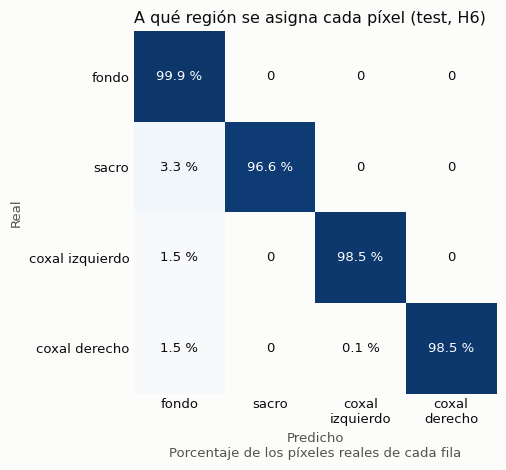

In [21]:
conf = informe["confusion_semantica"]
fig = r.figura_matriz(conf["filas_real_columnas_predicho"], conf["clases"],
                      "A qué región se asigna cada píxel (test, H6)", "Porcentaje de los píxeles reales de cada fila")
plt.show()

In [22]:
peores = pd.DataFrame(informe["peores_casos"]).set_index("caso").drop(columns=["panel"])
peores.T

caso,039,061,007,054,047
cortes,392.0000,350.0000,317.0000,301.0000,193.0000
fragmentos_por_corte,1003.0000,868.0000,665.0000,697.0000,506.0000
dice_fragmento,0.7839,0.8219,0.8313,0.8342,0.8535
dice_primario,0.8905,0.8912,0.9126,0.8989,0.8697
dice_secundario,0.6347,0.6352,0.5449,0.6629,0.7526
fragmentos_secundarios_por_corte,418.0000,235.0000,147.0000,191.0000,70.0000
secundarios_sin_pareja_%,7.7000,17.4000,24.5000,16.2000,17.1000
hueso_asignado_a_otra_region_%,0.1800,0.0000,0.0700,0.1200,0.0200
hueso_predicho_como_fondo_%,3.2200,1.2100,1.5900,2.8500,5.4100
dice_centro_15_85,0.7879,0.8062,0.8211,0.8346,0.8877


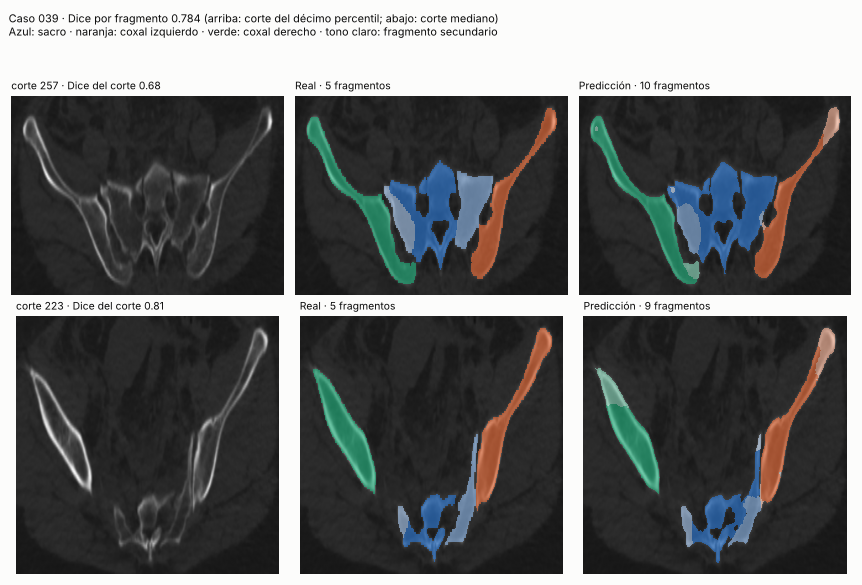

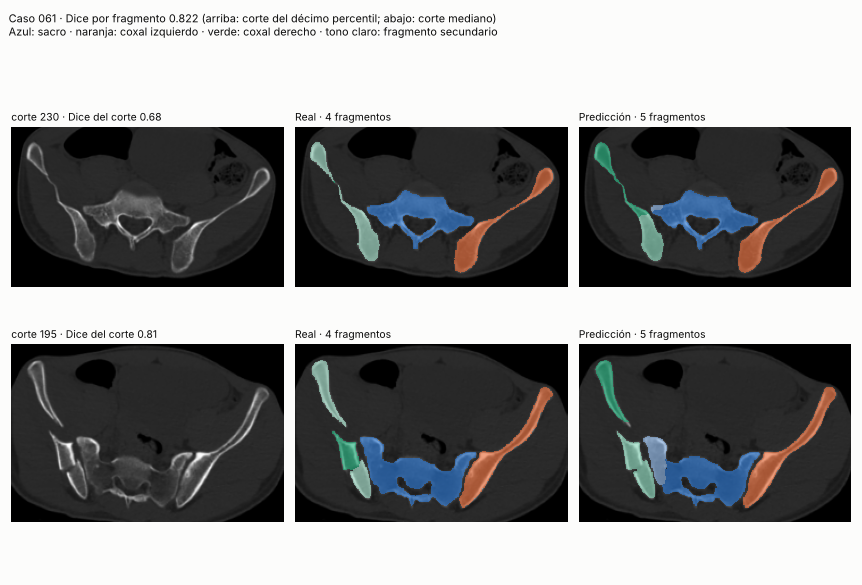

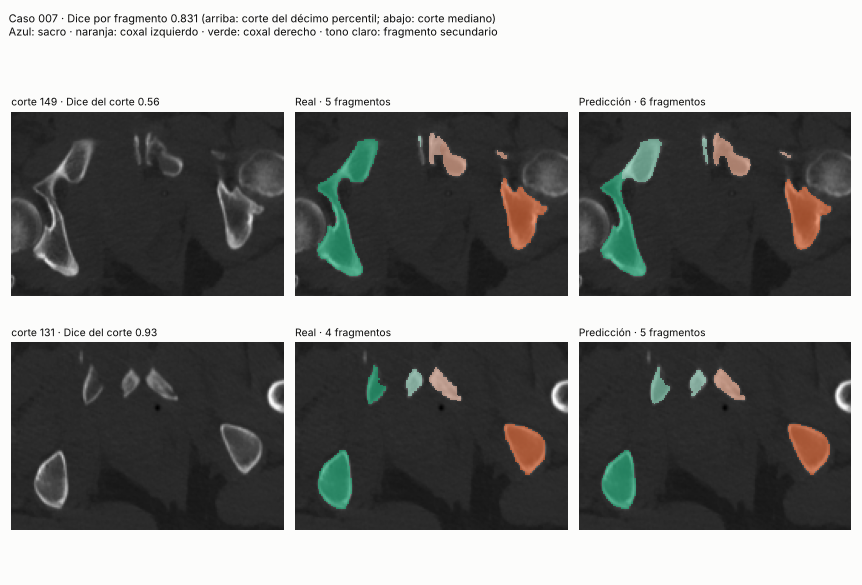

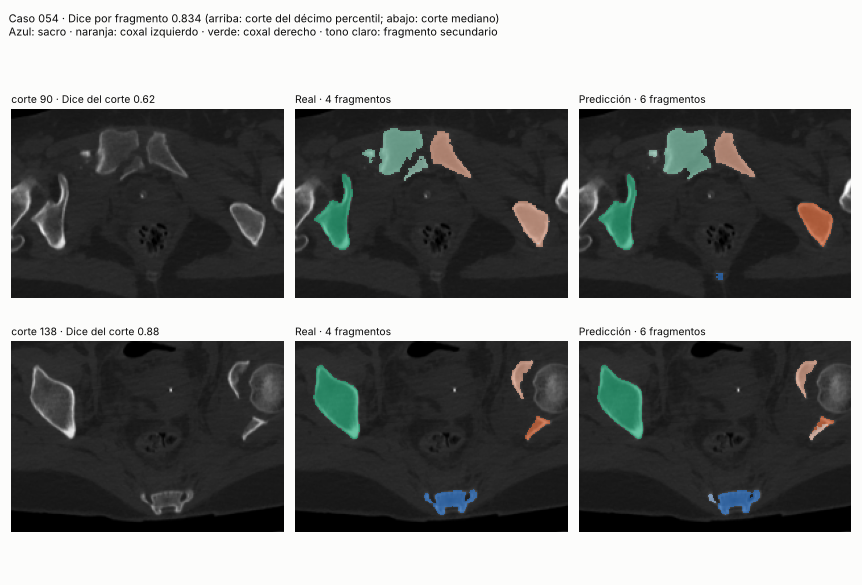

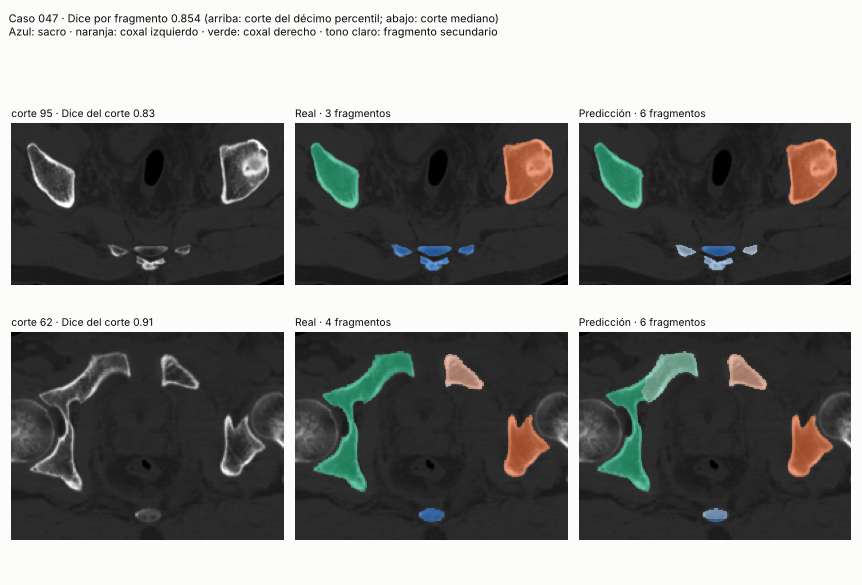

In [23]:
for fila in informe["peores_casos"]:
    display(Image(filename=str(r.S10 / "informe_h6_test" / fila["panel"])))

**Lectura.** La clasificación falla sobre todo en el sacro (56 cortes en que está y no se predice,
de 2 294). En la segmentación, la confusión entre regiones prácticamente desapareció: 0.06 % del
hueso se asigna a otra región (con D5 era 13.7 % en el caso 012 y 8.2 % en el 039). El error que
queda es hueso que se predice como fondo (1.9 %, más en el sacro: 3.3 %) y, sobre todo, **dónde se
parte el hueso en fragmentos**: en los cinco peores casos el Dice del fragmento principal es
0.87–0.91 y el de los secundarios 0.54–0.75, con entre 8 % y 25 % de secundarios sin pareja. El 039
tiene muchos fragmentos secundarios por corte y el 047 pierde en los extremos del volumen.

## 12. Latencia por corte

Corte de 384 × 384, lote 1, todo el pipeline (modelo, decodificación de cajas y separación de
fragmentos). Medida con D5; H6 tiene la misma arquitectura.

In [24]:
latencia = {}
for etiqueta, nombre in (("GPU (L4)", "latencia_gpu_L4"), ("CPU (12 hilos)", "latencia_cpu_colab")):
    latencia[etiqueta] = {config: valores["mediana_ms"] for config, valores in r.cargar(nombre)["config"].items()}
pd.DataFrame(latencia).rename_axis("mediana en ms")

,GPU (L4),CPU (12 hilos)
mediana en ms,,
1 modelo,63.7,161.7
1 modelo + TTA,71.6,249.6
ensamble 3 + TTA,87.4,518.0


**Lectura.** Un modelo con TTA tarda 72 ms en GPU y 250 ms en CPU: alcanza para la inferencia en
vivo de un corte en la demo. Falta medirla en el Mac del equipo.

## 13. Resumen y decisiones

| Tema | Decisión |
|---|---|
| Modelo final | H6: 32 canales, CBAM en 1 etapa, EMA, aumento geométrico con rotación ±35° y orientación canónica |
| Inferencia | Un modelo con TTA espejo. El ensamble no entra: gana menos que el ruido |
| Test | 0.845 en la primera evaluación (D5) y 0.875 en la segunda (H6). Se reportan las dos |
| Ablaciones | CBAM aporta en clasificación y detección; el transfer learning no aporta de forma consistente |
| Distancia | Se mide sobre el volumen sin relleno. Error medio 1.28 mm en test, dominado por un fragmento |
| SAM zero-shot | En test, 0.889 de Dice por región frente a 0.934 del sistema propio |
| Descartado | 2.5D, focal, Tversky, supervisión profunda, sobremuestreo, 48 canales, λ ×2, detector geométrico de giro |

**Pendiente:** latencia en el Mac y llevar H6 con el paso de orientación canónica al dashboard de
la Semana 11.

**Limitaciones:** los fragmentos secundarios son la parte más débil (Dice 0.750 en test); fragmentos
en contacto pueden fusionarse; el modelo depende de que la cabecera del volumen indique bien la
orientación.